<a href="https://colab.research.google.com/github/sit-sophiahsg/3001-CVDL/blob/colab-model/CVDL_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **INF3001 Computer Vision & Deep Learning -- Project**

**P1-9**:
| Members | Student ID |
|---------|------------|
| Gador Sophia Helen Santiago | 2503845 |
| Natalie Peh | |
| Tan Jian Ying Ivan | |
| Tan Jing Yu | |
| Tan Jun Ying | |

# **Setup & Reproducibility**


In [ ]:
# imports
# device
# seed

# **Dataset Preparation**

In [ ]:
#load dataset
# show dataset
# dataset desc (source, methods, annotations)
# data cleaning
# data distribution
# sample image

In [ ]:
!pip -q install -U kagglehub

In [ ]:
import kagglehub
from pathlib import Path

DATA_ROOT = Path(kagglehub.dataset_download('swoyam2609/fresh-and-stale-classification'))
print(DATA_ROOT)
!ls "$DATA_ROOT"

100%|██████████| 2.84G/2.84G [00:26<00:00, 114MB/s] 

Extracting files...


/root/.cache/kagglehub/datasets/swoyam2609/fresh-and-stale-classification/versions/1
dataset


In [ ]:
# file counts and file types

from collections import Counter

ROOT = DATA_ROOT / 'dataset'

files = [p for p in ROOT.rglob('*') if p.is_file()]
print("Total files:", len(files))
print("Extensions:", Counter(p.suffix.lower() for p in files), "\n")

for d in sorted(p for p in ROOT.rglob('*') if p.is_dir()):
    depth = len(d.relative_to(ROOT).parts)
    n = sum(1 for f in d.iterdir() if f.is_file())
    print('  ' * (depth - 1) + f"{d.name}/  ({n} files)")

Total files: 30357
Extensions: Counter({'.png': 25819, '.jpg': 4538}) 

Test/  (0 files)
  freshapples/  (791 files)
  freshbanana/  (892 files)
  freshcucumber/  (279 files)
  freshokra/  (370 files)
  freshoranges/  (388 files)
  freshpatato/  (270 files)
  freshtamto/  (255 files)
  rottenapples/  (988 files)
  rottenbanana/  (900 files)
  rottencucumber/  (255 files)
  rottenokra/  (224 files)
  rottenoranges/  (403 files)
  rottenpatato/  (370 files)
  rottentamto/  (353 files)
Train/  (0 files)
  freshapples/  (2424 files)
  freshbanana/  (2468 files)
  freshbittergroud/  (327 files)
  freshcapsicum/  (990 files)
  freshcucumber/  (496 files)
  freshokra/  (635 files)
  freshoranges/  (1466 files)
  freshpotato/  (536 files)
  freshtomato/  (1858 files)
  rottenapples/  (3248 files)
  rottenbanana/  (2932 files)
  rottenbittergroud/  (357 files)
  rottencapsicum/  (901 files)
  rottencucumber/  (421 files)
  rottenokra/  (338 files)
  rottenoranges/  (1595 files)
  rottenpotato/ 

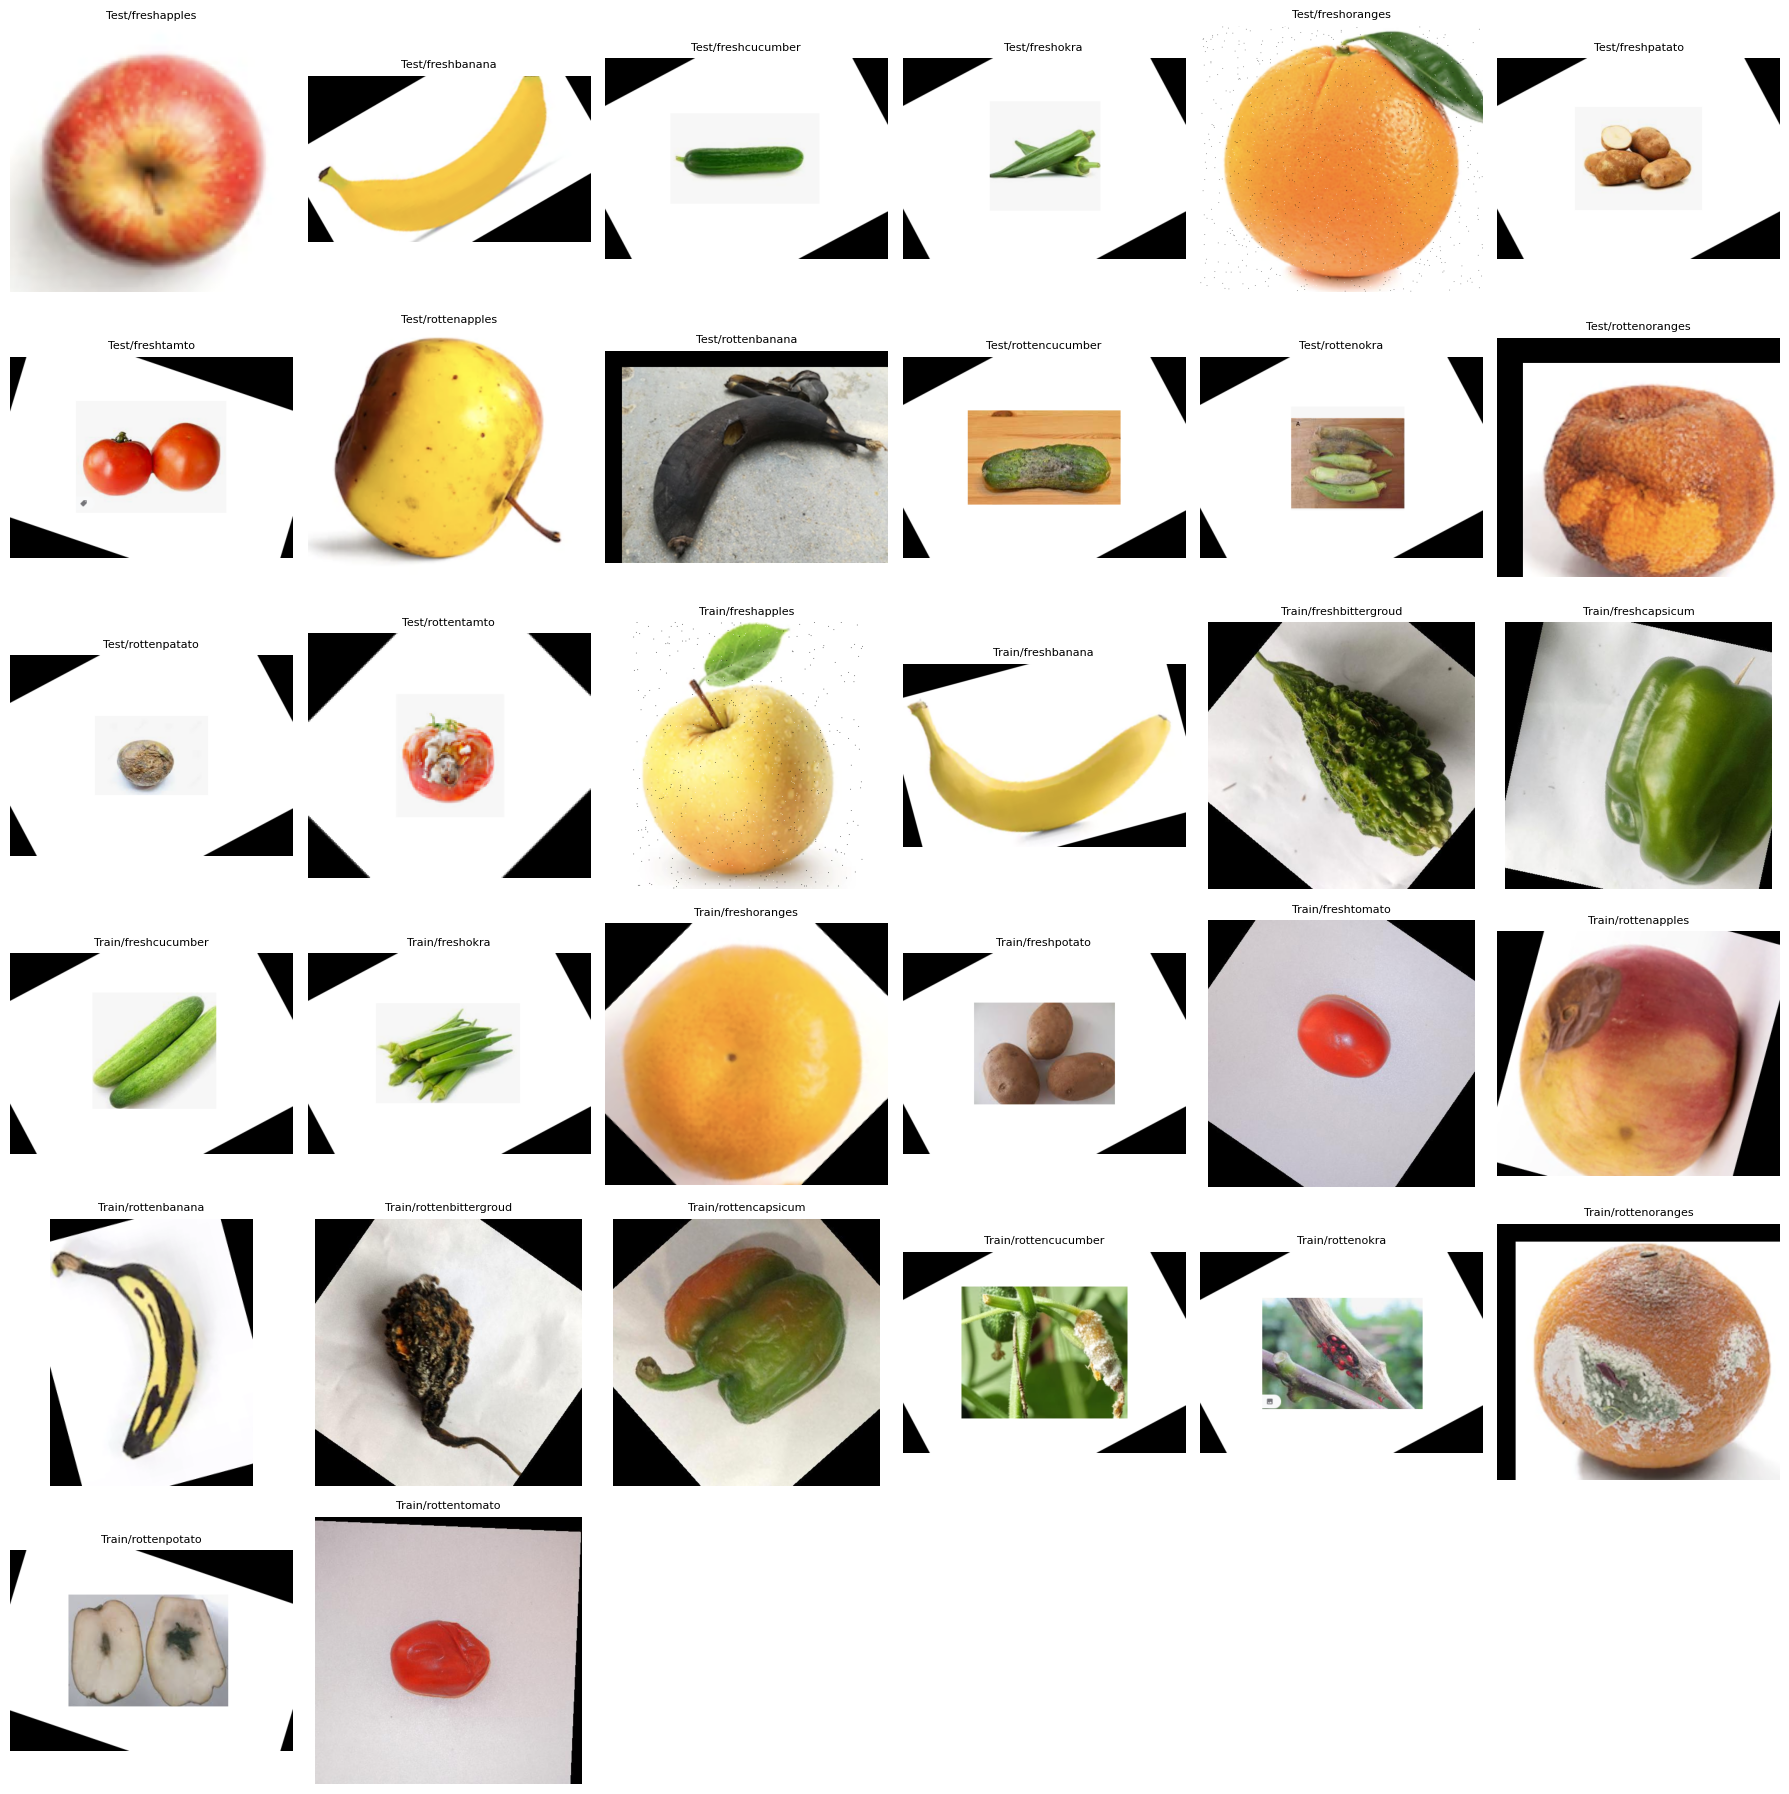

In [ ]:
# one image from each folder

import random, matplotlib.pyplot as plt
from PIL import Image

leaf_dirs = [d for d in sorted(ROOT.rglob('*')) if d.is_dir() and any(f.is_file() for f in d.iterdir())]
cols = 6
rows = -(-len(leaf_dirs) // cols)
plt.figure(figsize=(3 * cols, 3 * rows))
for i, d in enumerate(leaf_dirs):
    img_path = random.choice([f for f in d.iterdir() if f.is_file()])
    plt.subplot(rows, cols, i + 1)
    plt.imshow(Image.open(img_path).convert('RGB'))
    plt.title(str(d.relative_to(ROOT)), fontsize=8)
    plt.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
import pandas as pd

NAME_MAP = {
    'apples': 'apple', 'banana': 'banana', 'bittergroud': 'bitter_gourd',
    'capsicum': 'capsicum', 'cucumber': 'cucumber', 'okra': 'okra',
    'oranges': 'orange', 'potato': 'potato', 'patato': 'potato',
    'tomato': 'tomato', 'tamto': 'tomato',
}

rows = []
for p in ROOT.rglob('*'):
    if not p.is_file():
        continue
    split, folder = p.parent.parent.name, p.parent.name
    label = 'fresh' if folder.startswith('fresh') else 'rotten'
    produce = NAME_MAP[folder.removeprefix(label)]
    rows.append({'path': str(p), 'produce': produce, 'label': label,
                 'orig_split': split, 'ext': p.suffix.lower()})

df = pd.DataFrame(rows)
print(len(df), "images")
print(pd.crosstab(df.produce, df.label, margins=True))

30357 images
label         fresh  rotten    All
produce                           
apple          3215    4236   7451
banana         3360    3832   7192
bitter_gourd    327     357    684
capsicum        990     901   1891
cucumber        775     676   1451
okra           1005     562   1567
orange         1854    1998   3852
potato          806    1172   1978
tomato         2113    2178   4291
All           14445   15912  30357


# **Data Transformation & Augmentation**

In [ ]:
# split
# data loaders
# normalizing

In [ ]:
# grouping near duplicates
import numpy as np
from PIL import Image
from scipy.fft import dctn
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

def dihedral(a):                      # the 8 rotations/flips; index 0 = original
    out = []
    for k in range(4):
        r = np.rot90(a, k)
        out += [r, np.fliplr(r)]
    return out

def phash8(path):
    with Image.open(path) as im:
        a = np.asarray(im.convert('L').resize((32, 32), Image.LANCZOS), dtype=np.float32)
    hashes = []
    for t in dihedral(a):
        d = dctn(t, norm='ortho')[:8, :8]                 # low-frequency DCT block
        hashes.append(np.packbits((d > np.median(d)).ravel()).view('>u8')[0])
    return hashes

with ThreadPoolExecutor(8) as ex:
    H = np.array(list(tqdm(ex.map(phash8, df.path), total=len(df))), dtype=np.uint64)  # (N, 8)
print(H.shape)

  0%|          | 0/30357 [00:00<?, ?it/s]

(30357, 8)


In [ ]:
T = 4                                 # max differing bits out of 64 (conservative start)
N = len(H)

if hasattr(np, 'bitwise_count'):
    popcount = np.bitwise_count
else:
    LUT = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
    popcount = lambda x: LUT[x.view(np.uint8)].reshape(*x.shape, 8).sum(-1)

pairs, base = [], H[:, 0]
for s in tqdm(range(0, N, 64)):
    d = popcount(base[s:s+64, None, None] ^ H[None, :, :]).min(axis=2)   # (chunk, N)
    ii, jj = np.nonzero(d <= T)
    ii += s
    keep = ii != jj
    pairs.append(np.stack([ii[keep], jj[keep]], 1))
pairs = np.concatenate(pairs)
print("near-duplicate pairs:", len(pairs))

parent = np.arange(N)
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
for a, b in pairs:
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[max(ra, rb)] = min(ra, rb)

df['group'] = [find(i) for i in range(N)]
g = df.groupby('group')
sizes = g.size()
print(f"groups: {len(sizes)} | singletons: {(sizes == 1).sum()} | largest: {sizes.max()}")
print(sizes.value_counts().sort_index().head(15))
print("groups mixing fresh/rotten:", (g.label.nunique() > 1).sum())
print("groups mixing produce types:", (g.produce.nunique() > 1).sum())
train_groups = set(df.loc[df.orig_split == 'Train', 'group'])
print("Test images sharing a group with Train:",
      f"{df.loc[df.orig_split == 'Test', 'group'].isin(train_groups).mean():.1%}")

  0%|          | 0/475 [00:00<?, ?it/s]

near-duplicate pairs: 304775
groups: 13873 | singletons: 8919 | largest: 3104
1     8919
2     1820
3     1990
4      487
5      327
6      175
7       67
8       29
9       12
10      13
11       7
12       7
13       1
14       1
15       2
Name: count, dtype: int64
groups mixing fresh/rotten: 155
groups mixing produce types: 132
Test images sharing a group with Train: 77.0%


pairs per bit distance:
 0     51068
2     77756
4    175951
Name: count, dtype: int64 

3104 {'okra': 1141, 'potato': 1030, 'cucumber': 933} {'fresh': 1798, 'rotten': 1306}
1545 {'tomato': 1080, 'apple': 185, 'capsicum': 181, 'orange': 55, 'bitter_gourd': 41, 'banana': 3} {'rotten': 1045, 'fresh': 500}
892 {'tomato': 566, 'potato': 326} {'fresh': 566, 'rotten': 326}
113 {'tomato': 111, 'apple': 1, 'banana': 1} {'rotten': 113}
103 {'tomato': 103} {'rotten': 103}
52 {'tomato': 52} {'fresh': 52}
40 {'tomato': 38, 'apple': 2} {'rotten': 40}
39 {'banana': 39} {'fresh': 30, 'rotten': 9}

mixed-produce group sizes: [3104, 1545, 892, 113, 40, 20, 19, 18, 16, 14]


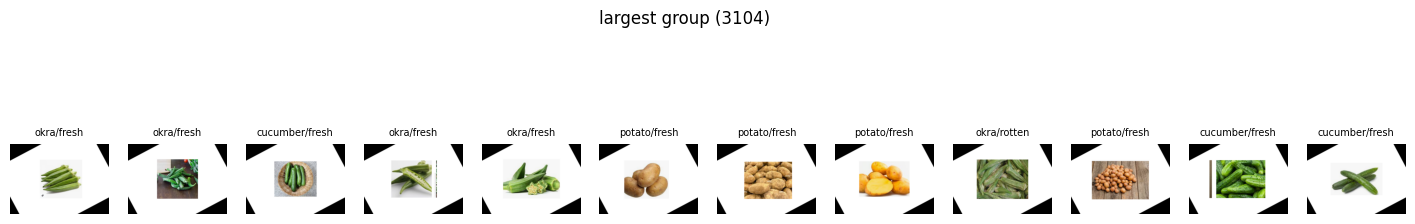

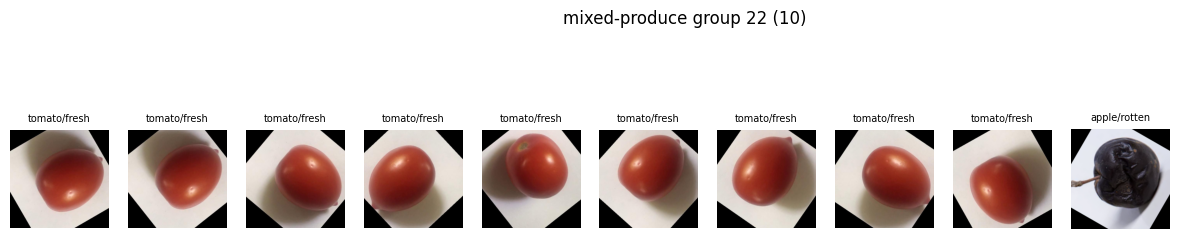

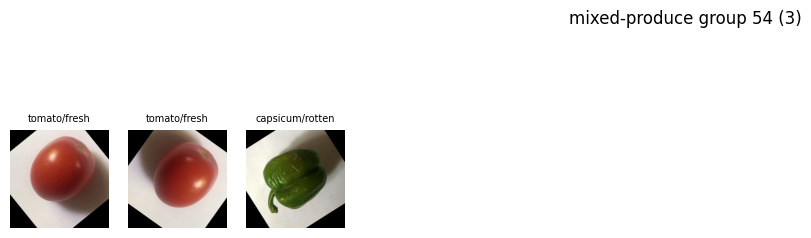

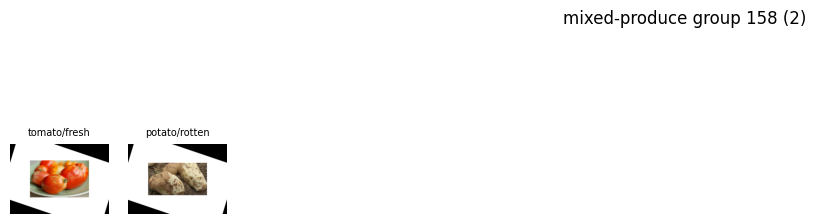

In [ ]:
import matplotlib.pyplot as plt

# 1) How far apart are the matched pairs?
pair_d = popcount(H[pairs[:, 0], 0][:, None] ^ H[pairs[:, 1]]).min(axis=1)
print("pairs per bit distance:\n", pd.Series(pair_d).value_counts().sort_index(), "\n")

# 2) What's inside the biggest groups?
for gid, n in sizes.sort_values(ascending=False).head(8).items():
    sub = df[df.group == gid]
    print(n, sub.produce.value_counts().to_dict(), sub.label.value_counts().to_dict())

mixed = sizes[g.produce.nunique() > 1]
print("\nmixed-produce group sizes:", mixed.sort_values(ascending=False).head(10).tolist())

# 3) Look at them
def show(paths, title):
    paths = list(paths)[:12]
    plt.figure(figsize=(18, 3.5))
    for i, p in enumerate(paths):
        plt.subplot(1, 12, i + 1); plt.imshow(Image.open(p).convert('RGB')); plt.axis('off')
        plt.title('/'.join(df.loc[df.path == p, ['produce', 'label']].iloc[0]), fontsize=7)
    plt.suptitle(title); plt.show()

big = sizes.idxmax()
show(df[df.group == big].sample(12, random_state=0).path, f"largest group ({sizes.max()})")
small_mixed = mixed[mixed < 50].index[:3]
for gid in small_mixed:
    show(df[df.group == gid].path, f"mixed-produce group {gid} ({sizes[gid]})")

In [ ]:
def regroup(T):
    par = np.arange(N)
    def f(x):
        while par[x] != x:
            par[x] = par[par[x]]
            x = par[x]
        return x
    for a, b in pairs[pair_d <= T]:
        ra, rb = f(a), f(b)
        if ra != rb:
            par[max(ra, rb)] = min(ra, rb)
    return np.array([f(i) for i in range(N)])

results = {}
for T_ in [2, 0]:
    tmp = df.assign(group=regroup(T_))
    gg = tmp.groupby('group'); sz = gg.size()
    tr = set(tmp.loc[tmp.orig_split == 'Train', 'group'])
    results[T_] = tmp.group.values
    print(f"\n=== T = {T_} ===")
    print(f"groups: {len(sz)} | singletons: {(sz == 1).sum()} | largest: {sz.max()}")
    print("mixed produce:", (gg.produce.nunique() > 1).sum(),
          "| mixed label:", (gg.label.nunique() > 1).sum())
    print("Test sharing a group with Train:",
          f"{tmp.loc[tmp.orig_split == 'Test', 'group'].isin(tr).mean():.1%}")
    for gid, n in sz.sort_values(ascending=False).head(5).items():
        sub = tmp[tmp.group == gid]
        print("  ", n, sub.produce.value_counts().to_dict(), sub.label.value_counts().to_dict())


=== T = 2 ===
groups: 17248 | singletons: 11540 | largest: 1033
mixed produce: 79 | mixed label: 100
Test sharing a group with Train: 73.8%
   1033 {'okra': 384, 'cucumber': 338, 'potato': 311} {'fresh': 555, 'rotten': 478}
   450 {'tomato': 450} {'rotten': 450}
   260 {'tomato': 195, 'potato': 65} {'fresh': 195, 'rotten': 65}
   33 {'tomato': 33} {'rotten': 19, 'fresh': 14}
   24 {'tomato': 24} {'fresh': 19, 'rotten': 5}

=== T = 0 ===
groups: 19143 | singletons: 13113 | largest: 100
mixed produce: 33 | mixed label: 21
Test sharing a group with Train: 73.0%
   100 {'tomato': 100} {'rotten': 100}
   37 {'tomato': 37} {'rotten': 37}
   33 {'tomato': 33} {'rotten': 33}
   30 {'tomato': 30} {'rotten': 30}
   25 {'tomato': 25} {'rotten': 25}


  0%|          | 0/30357 [00:00<?, ?it/s]

same-produce pairs:      [ 0.   0.   2.6  4.8  7.7 14.6]
different-produce pairs: [ 3.1  4.3  7.4 10.4 14.5 23.1] (n=66806)


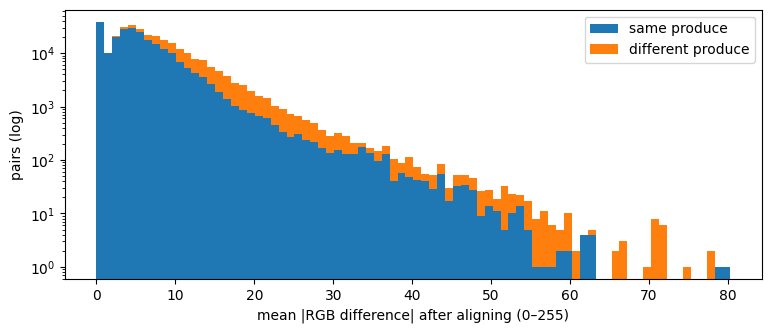

In [ ]:
def thumb(path):
    with Image.open(path) as im:
        return np.asarray(im.convert('RGB').resize((16, 16), Image.BILINEAR), dtype=np.int16)

with ThreadPoolExecutor(8) as ex:
    TH = np.stack(list(tqdm(ex.map(thumb, df.path), total=N)))          # (N, 16, 16, 3)

# which of the 8 variants of image b matched image a
best_t = popcount(H[pairs[:, 0], 0][:, None] ^ H[pairs[:, 1]]).argmin(axis=1)

A, B = TH[pairs[:, 0]], TH[pairs[:, 1]]
Bt = np.empty_like(B)
for t in range(8):                     # same order as dihedral(): t = 2k (+1 if flipped)
    m = best_t == t
    k, f = divmod(t, 2)
    r = np.rot90(B[m], k, axes=(1, 2))
    Bt[m] = r[:, :, ::-1] if f else r
col_d = np.abs(A - Bt).mean(axis=(1, 2, 3))      # 0–255 scale
del A, B, Bt

same_prod = df.produce.values[pairs[:, 0]] == df.produce.values[pairs[:, 1]]
q = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95]
print("same-produce pairs:     ", np.round(np.quantile(col_d[same_prod], q), 1))
print("different-produce pairs:", np.round(np.quantile(col_d[~same_prod], q), 1),
      f"(n={(~same_prod).sum()})")

plt.figure(figsize=(9, 3.5))
plt.hist([col_d[same_prod], col_d[~same_prod]], bins=80, stacked=True,
         label=['same produce', 'different produce'])
plt.yscale('log'); plt.xlabel('mean |RGB difference| after aligning (0–255)')
plt.ylabel('pairs (log)'); plt.legend(); plt.show()


=== colour cutoff 1.0 === pairs kept: 38161 (different-produce: 0)
groups: 19396 | singletons: 13383 | largest: 88
mixed produce: 0 | mixed label: 0 | Test sharing a group with Train: 73.4%

=== colour cutoff 2.0 === pairs kept: 47925 (different-produce: 12)
groups: 19107 | singletons: 13179 | largest: 265
mixed produce: 1 | mixed label: 2 | Test sharing a group with Train: 73.4%

=== colour cutoff 3.0 === pairs kept: 68545 (different-produce: 578)
groups: 18768 | singletons: 12948 | largest: 356
mixed produce: 6 | mixed label: 8 | Test sharing a group with Train: 73.4%


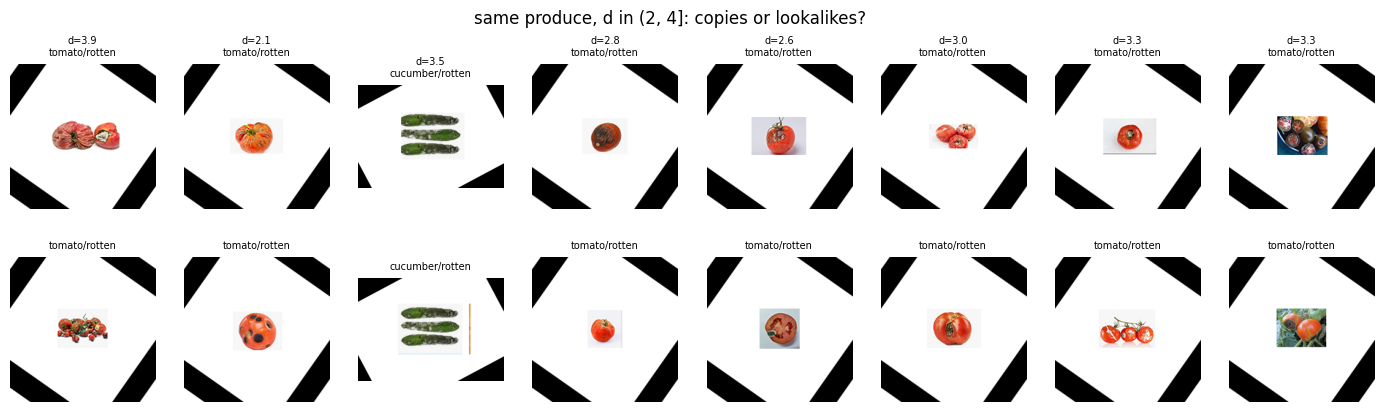

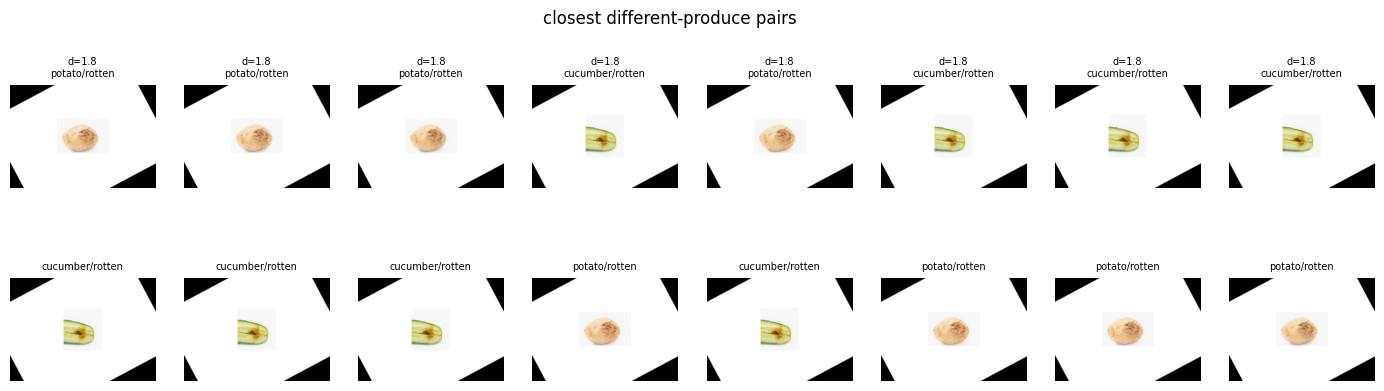

In [ ]:
def regroup_pairs(P):
    par = np.arange(N)
    def f(x):
        while par[x] != x:
            par[x] = par[par[x]]
            x = par[x]
        return x
    for a, b in P:
        ra, rb = f(a), f(b)
        if ra != rb:
            par[max(ra, rb)] = min(ra, rb)
    return np.array([f(i) for i in range(N)])

for C in [1.0, 2.0, 3.0]:
    keep = col_d <= C
    tmp = df.assign(group=regroup_pairs(pairs[keep]))
    gg = tmp.groupby('group'); sz = gg.size()
    tr = set(tmp.loc[tmp.orig_split == 'Train', 'group'])
    print(f"\n=== colour cutoff {C} === pairs kept: {keep.sum()} "
          f"(different-produce: {(keep & ~same_prod).sum()})")
    print(f"groups: {len(sz)} | singletons: {(sz == 1).sum()} | largest: {sz.max()}")
    print("mixed produce:", (gg.produce.nunique() > 1).sum(),
          "| mixed label:", (gg.label.nunique() > 1).sum(),
          "| Test sharing a group with Train:",
          f"{tmp.loc[tmp.orig_split == 'Test', 'group'].isin(tr).mean():.1%}")

def show_pairs(idx, title):
    n = len(idx)
    plt.figure(figsize=(2.2 * n, 4.6))
    for j, i in enumerate(idx):
        for r, p in enumerate(pairs[i]):
            plt.subplot(2, n, r * n + j + 1)
            plt.imshow(Image.open(df.path[p]).convert('RGB')); plt.axis('off')
            lbl = f"{df.produce[p]}/{df.label[p]}"
            plt.title(f"d={col_d[i]:.1f}\n{lbl}" if r == 0 else lbl, fontsize=7)
    plt.suptitle(title); plt.show()

rng = np.random.default_rng(0)
band = np.where(same_prod & (col_d > 2) & (col_d <= 4))[0]
show_pairs(rng.choice(band, 8, replace=False), "same produce, d in (2, 4]: copies or lookalikes?")
cross = np.where(~same_prod)[0]
show_pairs(cross[np.argsort(col_d[cross])[:8]], "closest different-produce pairs")

In [ ]:
# Lock in the grouping
df['group'] = regroup_pairs(pairs[col_d <= 1.0])
sz = df.groupby('group').size()
print(f"FINAL groups: {len(sz)} | singletons: {(sz == 1).sum()} | largest: {sz.max()}")

# Black-corner frame: mean of each 2x2 corner block of the 16x16 thumbnail is near black
corners = np.stack([TH[:, :2, :2], TH[:, :2, -2:], TH[:, -2:, :2], TH[:, -2:, -2:]], 1)
dark = (corners.mean(axis=(2, 3, 4)) < 25).sum(axis=1) >= 3
df['black_frame'] = dark
print(f"\nimages with black-corner frame: {dark.mean():.1%}\n")
print((pd.crosstab(df.produce, df.label, values=df.black_frame, aggfunc='mean') * 100).round(1))

FINAL groups: 19396 | singletons: 13383 | largest: 88

images with black-corner frame: 25.1%

label         fresh  rotten
produce                    
apple          34.6    33.1
banana         11.7     8.9
bitter_gourd   50.2    57.1
capsicum       54.1    53.7
cucumber        0.0     0.0
okra            0.0     0.0
orange         29.3    31.4
potato          0.0     0.1
tomato         25.4    58.5


# **Baseline Model**

In [ ]:
# default config

In [ ]:
# splitting

from sklearn.model_selection import StratifiedGroupKFold

strata = df.produce + '_' + df.label + '_' + df.black_frame.map({True: 'frame', False: 'clean'})
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=42)
fold = np.empty(len(df), dtype=int)
for k, (_, idx) in enumerate(sgkf.split(df, strata, groups=df.group)):
    fold[idx] = k
df['split'] = np.select([fold < 3, fold < 6], ['test', 'val'], 'train')

# Checks
assert df.groupby('group').split.nunique().max() == 1, "a group crosses splits!"
print(df.split.value_counts(normalize=True).round(3), "\n")
print(pd.crosstab([df.produce, df.label], df.split), "\n")
print("frame rate per split (%):\n",
      (df.groupby(['split', 'produce']).black_frame.mean().unstack(0) * 100).round(1))

# Save the manifest (paths relative to the dataset root, so it works in any session)
df['rel_path'] = df.path.map(lambda p: str(Path(p).relative_to(ROOT)))
cols = ['rel_path', 'produce', 'label', 'orig_split', 'ext', 'group', 'black_frame', 'split']
df[cols].to_csv('/content/split_manifest.csv', index=False)
print("saved", len(df), "rows")

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:1023: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=20.
  warnings.warn(


split
train    0.701
val      0.150
test     0.149
Name: proportion, dtype: float64 

split                test  train  val
produce      label                   
apple        fresh    503   2221  491
             rotten   616   3002  618
banana       fresh    485   2387  488
             rotten   569   2656  607
bitter_gourd fresh     46    233   48
             rotten    55    252   50
capsicum     fresh    142    694  154
             rotten   133    635  133
cucumber     fresh    120    529  126
             rotten    96    485   95
okra         fresh    149    706  150
             rotten    97    366   99
orange       fresh    274   1300  280
             rotten   293   1423  282
potato       fresh    120    576  110
             rotten   184    800  188
tomato       fresh    321   1486  306
             rotten   308   1538  332 

frame rate per split (%):
 split         test  train   val
produce                        
apple         31.8   33.6  36.3
banana        10.1   10.3   9

In [ ]:
# change all to jpeg format

from collections import Counter

# Where were the JPGs, and could two files collide once both become .jpg?
print(pd.crosstab([df.produce, df.label], df.ext), "\n")
OUT = Path('/content/produce_jpg')
df['jpg_rel'] = df.rel_path.map(lambda r: str(Path(r).with_suffix('.jpg')))
dupes = df.jpg_rel.duplicated(keep=False)
print("name collisions:", dupes.sum())
df.loc[dupes, 'jpg_rel'] = df.loc[dupes].apply(          # keep both if any
    lambda r: str(Path(r.rel_path).with_name(Path(r.rel_path).stem + '_' + r.ext[1:] + '.jpg')), axis=1)

def reencode(rel_src, rel_dst):
    dst = OUT / rel_dst
    dst.parent.mkdir(parents=True, exist_ok=True)
    with Image.open(ROOT / rel_src) as im:
        had_alpha = im.mode in ('RGBA', 'LA') or (im.mode == 'P' and 'transparency' in im.info)
        if had_alpha:
            im = im.convert('RGBA')
            bg = Image.new('RGB', im.size, (255, 255, 255))
            bg.paste(im, mask=im.getchannel('A'))
            im = bg
        else:
            im = im.convert('RGB')
        orig = im.size
        im.thumbnail((512, 512), Image.LANCZOS)
        im.save(dst, 'JPEG', quality=95)
    return had_alpha, orig

with ThreadPoolExecutor(8) as ex:
    res = list(tqdm(ex.map(reencode, df.rel_path, df.jpg_rel), total=len(df)))
df['had_alpha'] = [r[0] for r in res]
df['orig_w'] = [r[1][0] for r in res]
df['orig_h'] = [r[1][1] for r in res]

print("\nimages with transparency:", df.had_alpha.sum())
print("original size (w x h) quantiles:\n", df[['orig_w', 'orig_h']].quantile([0, .05, .5, .95, 1]))
print("re-encoded files:", sum(1 for _ in OUT.rglob('*.jpg')))

cols = ['rel_path', 'jpg_rel', 'produce', 'label', 'orig_split', 'ext', 'group',
        'black_frame', 'had_alpha', 'orig_w', 'orig_h', 'split']
df[cols].to_csv('/content/split_manifest.csv', index=False)

ext                  .jpg  .png
produce      label             
apple        fresh      0  3215
             rotten     0  4236
banana       fresh      0  3360
             rotten     0  3832
bitter_gourd fresh    327     0
             rotten   357     0
capsicum     fresh    990     0
             rotten   901     0
cucumber     fresh      0   775
             rotten     0   676
okra         fresh      0  1005
             rotten     0   562
orange       fresh      0  1854
             rotten     0  1998
potato       fresh      0   806
             rotten     0  1172
tomato       fresh    981  1132
             rotten   982  1196 

name collisions: 0


  0%|          | 0/30357 [00:00<?, ?it/s]


images with transparency: 2248
original size (w x h) quantiles:
       orig_w  orig_h
0.00   144.0   116.0
0.05   200.0   182.0
0.50   450.0   356.0
0.95   622.0   512.0
1.00   862.0   518.0
re-encoded files: 30357


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
DRIVE_DIR = Path('/content/drive/MyDrive/AAI3001_Group9/data')
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

!cp /content/split_manifest.csv "{DRIVE_DIR}/"
!cd /content && zip -qr "{DRIVE_DIR}/produce_jpg.zip" produce_jpg
!ls -lh "{DRIVE_DIR}"

Mounted at /content/drive
total 829M
-rw------- 1 root root 824M Oct  6 17:18 produce_jpg.zip
-rw------- 1 root root 4.7M Oct  6 17:18 split_manifest.csv


In [ ]:
print(pd.crosstab([df.produce, df.label], df.had_alpha))

had_alpha            False  True 
produce      label               
apple        fresh    2897    318
             rotten   3739    497
banana       fresh    2961    399
             rotten   3229    603
bitter_gourd fresh     327      0
             rotten    357      0
capsicum     fresh     990      0
             rotten    901      0
cucumber     fresh     775      0
             rotten    676      0
okra         fresh    1005      0
             rotten    562      0
orange       fresh    1648    206
             rotten   1776    222
potato       fresh     806      0
             rotten   1171      1
tomato       fresh    2111      2
             rotten   2178      0


In [ ]:
# ===== 0. Setup and reproducibility =====
import os, copy, math, time, random, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision import models

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             f1_score, cohen_kappa_score)
from sklearn.manifold import TSNE

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('device:', device, '| torch', torch.__version__)

CFG = dict(
    # ---- data ----
    data_dir='/content/produce_jpg',
    csv_path='/content/split_manifest.csv',
    drive_dir='/content/drive/MyDrive/AAI3001_Group9/data',
    csv_annotator2='',
    ood_dir='data/ood',
    use_dummy_data=False,
    produce_classes=['apple', 'banana', 'bitter_gourd', 'capsicum', 'cucumber',
                     'okra', 'orange', 'potato', 'tomato'],
    stage_classes=['Fresh', 'Rotten'],
    img_size=224, batch_size=32, num_workers=2,
    balanced_sampler=True, sampler_power=1.0,

    # ---- model / training ----
    backbones=['mobilenet_v3_large', 'resnet50', 'convnext_tiny'],
    stage_losses=['ce'],
    lrates=[1e-3, 3e-4, 1e-4],
    search_epochs=4, max_epochs=20, patience=5,
    head_only_epochs=2, backbone_lr_mult=0.1,
    weight_decay=1e-4, label_smoothing=0.05, dropout=0.2,
    loss_weights=dict(produce=0.5, stage=1.0, days=0.0),
    use_days_head=False,
    selection_metric='stage_f1',
    seed=42, out_dir='outputs',
)
os.makedirs(CFG['out_dir'], exist_ok=True)
PRODUCE, STAGES = CFG['produce_classes'], CFG['stage_classes']
K = len(STAGES)
SPOILED = STAGES.index('Rotten')

def seed_everything(seed):
    # Lecture 2: seed all random generators for reproducible experiments
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(CFG['seed'])
print(len(PRODUCE), 'produce types |', STAGES)

device: cuda:0 | torch 2.11.0+cu130
9 produce types | ['Fresh', 'Rotten']


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
# ===== 1-3. Data, split, transforms, Dataset, DataLoaders =====
if not os.path.isdir(CFG['data_dir']):                      # restore after a runtime reset
    from google.colab import drive; drive.mount('/content/drive')
    !unzip -q "{CFG['drive_dir']}/produce_jpg.zip" -d /content
    !cp "{CFG['drive_dir']}/split_manifest.csv" /content/

m = pd.read_csv(CFG['csv_path'])
df = pd.DataFrame({'path': m['jpg_rel'], 'item_id': 'g' + m['group'].astype(str),
                   'produce': m['produce'], 'stage': m['label'].str.capitalize(),
                   'split': m['split'], 'black_frame': m['black_frame']})
df['produce_idx'] = df['produce'].map({c: i for i, c in enumerate(PRODUCE)})
df['stage_idx'] = df['stage'].map({c: i for i, c in enumerate(STAGES)})
df['days_to_next'] = np.nan                                  # days head is off
assert df[['produce_idx', 'stage_idx']].notna().all().all()

def group_split(df, seed):
    # Split fixed in the manifest (near-duplicate groups, stratified by produce x label x frame)
    pick = lambda s: df[df['split'] == s].reset_index(drop=True)
    return pick('train'), pick('val'), pick('test')

df_train, df_val, df_test = group_split(df, CFG['seed'])
print({n: len(d) for n, d in [('train', df_train), ('val', df_val), ('test', df_test)]})

# ---- 2. Transforms (Lab 4) ----
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
S = CFG['img_size']
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.6, 1.0), ratio=(0.8, 1.25)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.15, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
test_transforms = transforms.Compose([
    transforms.Resize(int(S * 1.14)),
    transforms.CenterCrop(S),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
def denorm(t):
    return (t.permute(1, 2, 0).cpu().numpy() * np.array(STD) + np.array(MEAN)).clip(0, 1)

# ---- 3. Dataset + DataLoaders (Lecture 2 map-style Dataset) ----
class ProduceDataset(torch.utils.data.Dataset):
    def __init__(self, frame, root, transform):
        super().__init__()
        self.frame = frame.reset_index(drop=True)
        self.root = root
        self.transform = transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, i):
        r = self.frame.iloc[i]
        img = self.transform(Image.open(os.path.join(self.root, r['path'])).convert('RGB'))
        has_days = not pd.isna(r['days_to_next'])
        return (img, torch.tensor(int(r['produce_idx'])), torch.tensor(int(r['stage_idx'])),
                torch.tensor(float(r['days_to_next']) if has_days else 0.0),
                torch.tensor(1.0 if has_days else 0.0))

ds = {'train': ProduceDataset(df_train, CFG['data_dir'], train_transforms),
      'val':   ProduceDataset(df_val,   CFG['data_dir'], test_transforms),
      'test':  ProduceDataset(df_test,  CFG['data_dir'], test_transforms)}

def make_train_sampler(frame, power=CFG['sampler_power']):
    # every produce x stage cell drawn equally often (power=1); 0.5 = softer
    cell = frame['produce_idx'] * K + frame['stage_idx']
    w = (1.0 / cell.map(cell.value_counts())) ** power
    return torch.utils.data.WeightedRandomSampler(torch.tensor(w.values, dtype=torch.double), len(w), replacement=True)

B, NW = CFG['batch_size'], CFG['num_workers']
dataloaders = {
    'train': torch.utils.data.DataLoader(ds['train'], batch_size=B, num_workers=NW,
                                         sampler=make_train_sampler(df_train)),
    'val':   torch.utils.data.DataLoader(ds['val'],  batch_size=B, shuffle=False, num_workers=NW),
    'test':  torch.utils.data.DataLoader(ds['test'], batch_size=B, shuffle=False, num_workers=NW),
}
xb = next(iter(dataloaders['train']))
print('batch shapes:', [tuple(t.shape) for t in xb])
if device.type == 'cpu':
    print('WARNING: still on CPU. Switch to a T4 GPU before training.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'train': 21289, 'val': 4557, 'test': 4511}
batch shapes: [(32, 3, 224, 224), (32,), (32,), (32,), (32,)]


In [ ]:
# ===== 4-5. Model (pretrained backbone + heads) and loss =====
def build_backbone(name, pretrained=True):
    # Returns (feature extractor without classifier, feature dim, layer used for Grad-CAM)
    w = 'DEFAULT' if pretrained else None
    if name == 'resnet50':
        m = models.resnet50(weights=w); feat = m.fc.in_features; m.fc = nn.Identity(); cam = m.layer4[-1]
    elif name == 'mobilenet_v3_large':
        m = models.mobilenet_v3_large(weights=w); feat = m.classifier[0].in_features; m.classifier = nn.Identity(); cam = m.features[-1]
    elif name == 'efficientnet_b0':
        m = models.efficientnet_b0(weights=w); feat = m.classifier[1].in_features; m.classifier = nn.Identity(); cam = m.features[-1]
    elif name == 'convnext_tiny':
        m = models.convnext_tiny(weights=w); feat = m.classifier[2].in_features; m.classifier[2] = nn.Identity(); cam = m.features[-1]
    else:
        raise ValueError(name)
    return m, feat, cam


class MultiTaskNet(nn.Module):
    def __init__(self, backbone_name, n_produce, n_stage, stage_loss='ce', pretrained=True, dropout=0.2,
                 use_days_head=CFG['use_days_head']):
        super().__init__()
        self.backbone, feat, self.cam_layer = build_backbone(backbone_name, pretrained)
        self.stage_loss = stage_loss
        self.drop = nn.Dropout(dropout)
        self.produce_head = nn.Linear(feat, n_produce)
        self.stage_head = nn.Linear(feat, n_stage - 1 if stage_loss == 'ordinal' else n_stage)
        self.days_head = nn.Sequential(nn.Linear(feat, 64), nn.ReLU(), nn.Linear(64, 1)) if use_days_head else None

    def heads(self):
        return [h for h in (self.produce_head, self.stage_head, self.days_head) if h is not None]

    def forward(self, x):
        f = self.backbone(x)
        h = self.drop(f)
        days = (F.softplus(self.days_head(h)).squeeze(1) if self.days_head is not None
                else torch.zeros(x.shape[0], device=x.device))      # head off: placeholder keeps the interface
        return {'produce': self.produce_head(h), 'stage': self.stage_head(h), 'days': days, 'feat': f}


def count_params(model):
    return sum(p.numel() for p in model.parameters()) / 1e6


def stage_logits_to_probs(logits, mode):
    if mode == 'ce':
        return logits.softmax(1)
    p_gt = torch.sigmoid(logits)
    ones, zeros = torch.ones_like(p_gt[:, :1]), torch.zeros_like(p_gt[:, :1])
    cum = torch.cat([ones, p_gt, zeros], 1)
    probs = (cum[:, :-1] - cum[:, 1:]).clamp(min=0)
    return probs / probs.sum(1, keepdim=True).clamp(min=1e-8)

def stage_predict(logits, mode):
    if mode == 'ce':
        return logits.argmax(1)
    return (torch.sigmoid(logits) > 0.5).sum(1)


class MultiTaskLoss(nn.Module):
    def __init__(self, mode, n_stage, weights, label_smoothing=0.0):
        super().__init__()
        self.mode, self.K, self.w, self.ls = mode, n_stage, weights, label_smoothing

    def forward(self, out, produce_y, stage_y, days_y, days_mask):
        l_prod = F.cross_entropy(out['produce'], produce_y, label_smoothing=self.ls)
        if self.mode == 'ce':
            l_stage = F.cross_entropy(out['stage'], stage_y, label_smoothing=self.ls)
        else:
            thresholds = torch.arange(self.K - 1, device=stage_y.device).unsqueeze(0)
            levels = (stage_y.unsqueeze(1) > thresholds).float()
            l_stage = F.binary_cross_entropy_with_logits(out['stage'], levels)
        if days_mask.sum() > 0:
            l_days = (F.smooth_l1_loss(out['days'], days_y, reduction='none') * days_mask).sum() / days_mask.sum()
        else:
            l_days = out['days'].sum() * 0.0
        total = self.w['produce'] * l_prod + self.w['stage'] * l_stage + self.w['days'] * l_days
        return total, {'produce': l_prod.item(), 'stage': l_stage.item(), 'days': l_days.item()}


# Sanity check, step 1 of the course recipe: initial loss
seed_everything(CFG['seed'])
m0 = MultiTaskNet(CFG['backbones'][0], len(PRODUCE), K, 'ce', dropout=CFG['dropout']).to(device).eval()
crit0 = MultiTaskLoss('ce', K, CFG['loss_weights'])
with torch.no_grad():
    _, parts = crit0(m0(xb[0].to(device)), *[t.to(device) for t in xb[1:]])
print(f"params: {count_params(m0):.2f}M | heads: {len(m0.heads())}")
print('initial produce loss', round(parts['produce'], 3), '| expected about', round(math.log(len(PRODUCE)), 3))
print('initial stage loss  ', round(parts['stage'], 3), '| expected about', round(math.log(K), 3))

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 189MB/s]


params: 2.98M | heads: 2
initial produce loss 2.239 | expected about 2.197
initial stage loss   0.762 | expected about 0.693


In [ ]:
# Step 2 of the course recipe: overfit one small batch
print('device:', device)
opt0 = optim.AdamW(m0.parameters(), lr=1e-3)
x_small, ys_small = xb[0][:8].to(device), [t[:8].to(device) for t in xb[1:]]
m0.train()
for it in range(60):
    loss, parts = crit0(m0(x_small), *ys_small)
    opt0.zero_grad(); loss.backward(); opt0.step()
    if it % 15 == 0 or it == 59:
        print(f"  overfit iter {it:2d}: loss {loss.item():.4f} | produce {parts['produce']:.4f} | stage {parts['stage']:.4f}")
del m0, opt0
if torch.cuda.is_available(): torch.cuda.empty_cache()

device: cuda:0
  overfit iter  0: loss 1.8084 | produce 2.2878 | stage 0.6644
  overfit iter 15: loss 0.0006 | produce 0.0005 | stage 0.0003
  overfit iter 30: loss 0.0001 | produce 0.0000 | stage 0.0000
  overfit iter 45: loss 0.0000 | produce 0.0000 | stage 0.0000
  overfit iter 59: loss 0.0000 | produce 0.0000 | stage 0.0000


In [ ]:
# ===== 6. Metrics =====
COST = np.array([[0, 1],     # true Fresh : predicting Rotten wastes good food
                 [10, 0]])   # true Rotten: selling it is the worst outcome

@torch.no_grad()
def predict(model, dataloader, device, mode):
    model.eval()
    keys = ['produce_y', 'stage_y', 'days_y', 'days_mask', 'produce_pred', 'stage_pred', 'days_pred',
            'produce_logits', 'stage_probs', 'feat']
    res = {k: [] for k in keys}
    for data in dataloader:
        inputs = data[0].to(device)
        out = model(inputs)
        res['produce_y'].append(data[1]); res['stage_y'].append(data[2])
        res['days_y'].append(data[3]); res['days_mask'].append(data[4])
        res['produce_logits'].append(out['produce'].cpu())
        res['produce_pred'].append(out['produce'].argmax(1).cpu())
        res['stage_pred'].append(stage_predict(out['stage'], mode).cpu())
        res['stage_probs'].append(stage_logits_to_probs(out['stage'], mode).cpu())
        res['days_pred'].append(out['days'].cpu()); res['feat'].append(out['feat'].cpu())
    return {k: torch.cat(v).numpy() for k, v in res.items()}

def compute_metrics(r):
    m = {}
    m['produce_acc'] = float((r['produce_pred'] == r['produce_y']).mean())
    m['stage_acc'] = float((r['stage_pred'] == r['stage_y']).mean())
    m['stage_f1'] = float(f1_score(r['stage_y'], r['stage_pred'], average='macro', labels=range(K), zero_division=0))
    spoiled = r['stage_y'] == SPOILED
    m['unsafe_sale_rate'] = float((r['stage_pred'][spoiled] != SPOILED).mean()) if spoiled.any() else float('nan')
    m['avg_cost'] = float(COST[r['stage_y'], r['stage_pred']].mean())
    msk = r['days_mask'] > 0
    m['days_mae'] = float(np.abs(r['days_pred'][msk] - r['days_y'][msk]).mean()) if msk.any() else float('nan')
    return m

def evaluate(model, dataloader, criterion, device, mode):
    r = predict(model, dataloader, device, mode)
    m = compute_metrics(r)
    if criterion is not None:
        model.eval(); tot, n = 0.0, 0
        with torch.no_grad():
            for data in dataloader:
                inputs = data[0].to(device); ys = [d.to(device) for d in data[1:]]
                loss, _ = criterion(model(inputs), *ys)
                tot += loss.item() * inputs.shape[0]; n += inputs.shape[0]
        m['loss'] = tot / n
    return m

In [ ]:
# ===== 7. Training functions (course structure) =====
def set_backbone_trainable(model, trainable):
    for p in model.backbone.parameters():
        p.requires_grad = trainable

def make_optimizer(model, lr):
    head_params = [p for h in model.heads() for p in h.parameters()]
    return optim.AdamW([{'params': model.backbone.parameters(), 'lr': lr * CFG['backbone_lr_mult']},
                        {'params': head_params, 'lr': lr}], weight_decay=CFG['weight_decay'])

def train_epoch(model, trainloader, criterion, device, optimizer, backbone_frozen=False):
    model.train()
    if backbone_frozen:
        model.backbone.eval()
    losses = []
    for data in trainloader:
        inputs = data[0].to(device)
        targets = [d.to(device) for d in data[1:]]
        outputs = model(inputs)
        loss, _ = criterion(outputs, *targets)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses

def train_modelcv(dataloader_cvtrain, dataloader_cvtest, model, criterion, optimizer, scheduler,
                  num_epochs, device, mode, patience=None, head_only_epochs=0, ckpt_path=None, verbose=True):
    best_measure, best_epoch, bestweights = -np.inf, -1, None
    history = []
    for epoch in range(num_epochs):
        frozen = epoch < head_only_epochs
        set_backbone_trainable(model, not frozen)
        t0 = time.time()
        losses = train_epoch(model, dataloader_cvtrain, criterion, device, optimizer, backbone_frozen=frozen)
        if scheduler is not None:
            scheduler.step()
        m = evaluate(model, dataloader_cvtest, criterion, device, mode)
        m.update(epoch=epoch, train_loss=float(np.mean(losses)), frozen=frozen, secs=time.time() - t0)
        history.append(m)
        measure = m[CFG['selection_metric']]
        if measure > best_measure:
            bestweights = copy.deepcopy(model.state_dict())
            best_measure, best_epoch = measure, epoch
            if ckpt_path:
                torch.save(bestweights, ckpt_path)
        if verbose:
            print(f"  ep {epoch:2d} {'[heads]' if frozen else '[all]  '} train_loss {m['train_loss']:.3f} | "
                  f"val_loss {m['loss']:.3f} stage_f1 {m['stage_f1']:.3f} unsafe {m['unsafe_sale_rate']:.3f} "
                  f"produce_acc {m['produce_acc']:.3f} | {m['secs']:.0f}s | best {best_measure:.3f}@{best_epoch}")
        if patience is not None and epoch - best_epoch >= patience and not frozen:
            print('  early stopping'); break
    return best_epoch, best_measure, bestweights, history

In [ ]:
# ===== 8. Steps 3-4: grid search with short runs (resumable) =====
grid_csv = os.path.join(CFG['drive_dir'], 'grid_search.csv')
results = pd.read_csv(grid_csv).to_dict('records') if os.path.exists(grid_csv) else []
done = {(r['backbone'], r['stage_loss'], r['lr']) for r in results}

for backbone in CFG['backbones']:
    for stage_loss in CFG['stage_losses']:
        for lr in CFG['lrates']:
            if (backbone, stage_loss, lr) in done:
                print(f'skip (done): {backbone} | {stage_loss} | lr={lr}'); continue
            print(f'\n### NEW RUN ### {backbone} | {stage_loss} | lr={lr}')
            seed_everything(CFG['seed'])
            model = MultiTaskNet(backbone, len(PRODUCE), K, stage_loss, dropout=CFG['dropout']).to(device)
            criterion = MultiTaskLoss(stage_loss, K, CFG['loss_weights'], CFG['label_smoothing'])
            optimizer = make_optimizer(model, lr)
            scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG['search_epochs'])
            best_epoch, best_measure, _, history = train_modelcv(
                dataloaders['train'], dataloaders['val'], model, criterion, optimizer, scheduler,
                CFG['search_epochs'], device, stage_loss, head_only_epochs=min(1, CFG['head_only_epochs']))
            results.append(dict(backbone=backbone, stage_loss=stage_loss, lr=lr, best_epoch=best_epoch,
                                params_M=round(count_params(model), 2),
                                **{f'val_{k}': v for k, v in history[best_epoch].items()
                                   if k not in ('epoch', 'frozen', 'secs', 'train_loss')}))
            pd.DataFrame(results).to_csv(grid_csv, index=False)          # save after every run
            del model, optimizer
            if torch.cuda.is_available(): torch.cuda.empty_cache()

search_df = pd.DataFrame(results).sort_values(f"val_{CFG['selection_metric']}", ascending=False)
search_df.to_csv(os.path.join(CFG['out_dir'], 'grid_search.csv'), index=False)
r0 = search_df.iloc[0]
best = dict(backbone=r0['backbone'], stage_loss=r0['stage_loss'], lr=float(r0['lr']),
            measure=float(r0[f"val_{CFG['selection_metric']}"]))
print('\nBest configuration:', best)
search_df[['backbone', 'lr', 'best_epoch', 'val_stage_acc', 'val_stage_f1', 'val_unsafe_sale_rate',
           'val_produce_acc', 'params_M']].round(4)


### NEW RUN ### mobilenet_v3_large | ce | lr=0.001
  ep  0 [heads] train_loss 0.578 | val_loss 0.452 stage_f1 0.924 unsafe 0.126 produce_acc 0.986 | 217s | best 0.924@0
  ep  1 [all]   train_loss 0.421 | val_loss 0.322 stage_f1 0.982 unsafe 0.022 produce_acc 0.995 | 229s | best 0.982@1
  ep  2 [all]   train_loss 0.332 | val_loss 0.303 stage_f1 0.989 unsafe 0.015 produce_acc 0.997 | 232s | best 0.989@2
  ep  3 [all]   train_loss 0.312 | val_loss 0.297 stage_f1 0.992 unsafe 0.010 produce_acc 0.997 | 230s | best 0.992@3

### NEW RUN ### mobilenet_v3_large | ce | lr=0.0003
  ep  0 [heads] train_loss 0.775 | val_loss 0.528 stage_f1 0.916 unsafe 0.132 produce_acc 0.979 | 215s | best 0.916@0
  ep  1 [all]   train_loss 0.494 | val_loss 0.359 stage_f1 0.970 unsafe 0.036 produce_acc 0.993 | 230s | best 0.970@1
  ep  2 [all]   train_loss 0.389 | val_loss 0.338 stage_f1 0.976 unsafe 0.035 produce_acc 0.997 | 228s | best 0.976@2
  ep  3 [all]   train_loss 0.366 | val_loss 0.330 stage_f1 0.979 unsa

100%|██████████| 97.8M/97.8M [00:00<00:00, 211MB/s]


  ep  0 [heads] train_loss 0.607 | val_loss 0.460 stage_f1 0.914 unsafe 0.144 produce_acc 0.985 | 243s | best 0.914@0
  ep  1 [all]   train_loss 0.373 | val_loss 0.305 stage_f1 0.986 unsafe 0.018 produce_acc 0.998 | 310s | best 0.986@1
  ep  2 [all]   train_loss 0.298 | val_loss 0.293 stage_f1 0.990 unsafe 0.015 produce_acc 0.997 | 312s | best 0.990@2
  ep  3 [all]   train_loss 0.284 | val_loss 0.285 stage_f1 0.992 unsafe 0.010 produce_acc 0.998 | 312s | best 0.992@3

### NEW RUN ### resnet50 | ce | lr=0.0003
  ep  0 [heads] train_loss 0.826 | val_loss 0.583 stage_f1 0.891 unsafe 0.182 produce_acc 0.979 | 246s | best 0.891@0
  ep  1 [all]   train_loss 0.428 | val_loss 0.333 stage_f1 0.981 unsafe 0.011 produce_acc 0.996 | 311s | best 0.981@1
  ep  2 [all]   train_loss 0.331 | val_loss 0.306 stage_f1 0.992 unsafe 0.009 produce_acc 0.997 | 314s | best 0.992@2
  ep  3 [all]   train_loss 0.316 | val_loss 0.303 stage_f1 0.994 unsafe 0.004 produce_acc 0.998 | 314s | best 0.994@3

### NEW RUN 

100%|██████████| 109M/109M [00:00<00:00, 133MB/s]


  ep  0 [heads] train_loss 0.524 | val_loss 0.411 stage_f1 0.950 unsafe 0.074 produce_acc 0.994 | 253s | best 0.950@0
  ep  1 [all]   train_loss 0.336 | val_loss 0.301 stage_f1 0.984 unsafe 0.025 produce_acc 0.999 | 579s | best 0.984@1
  ep  2 [all]   train_loss 0.280 | val_loss 0.280 stage_f1 0.993 unsafe 0.008 produce_acc 0.999 | 575s | best 0.993@2
  ep  3 [all]   train_loss 0.270 | val_loss 0.276 stage_f1 0.994 unsafe 0.007 produce_acc 0.999 | 576s | best 0.994@3

### NEW RUN ### convnext_tiny | ce | lr=0.0003
  ep  0 [heads] train_loss 0.669 | val_loss 0.468 stage_f1 0.926 unsafe 0.104 produce_acc 0.986 | 251s | best 0.926@0
  ep  1 [all]   train_loss 0.360 | val_loss 0.307 stage_f1 0.989 unsafe 0.017 produce_acc 0.999 | 579s | best 0.989@1
  ep  2 [all]   train_loss 0.300 | val_loss 0.292 stage_f1 0.991 unsafe 0.012 produce_acc 0.999 | 577s | best 0.991@2
  ep  3 [all]   train_loss 0.287 | val_loss 0.288 stage_f1 0.993 unsafe 0.008 produce_acc 1.000 | 580s | best 0.993@3

### NEW

,backbone,lr,best_epoch,val_stage_acc,val_stage_f1,val_unsafe_sale_rate,val_produce_acc,params_M
4,resnet50,0.0003,3,0.9939,0.9938,0.0037,0.9976,23.53
6,convnext_tiny,0.0010,3,0.9936,0.9936,0.0071,0.9993,27.83
7,convnext_tiny,0.0003,3,0.9934,0.9934,0.0079,0.9996,27.83
0,mobilenet_v3_large,0.0010,3,0.9923,0.9923,0.0100,0.9971,2.98
3,resnet50,0.0010,3,0.9923,0.9923,0.0100,0.9980,23.53
8,convnext_tiny,0.0001,3,0.9884,0.9883,0.0133,0.9989,27.83
1,mobilenet_v3_large,0.0003,3,0.9794,0.9793,0.0283,0.9971,2.98
5,resnet50,0.0001,3,0.9761,0.9760,0.0295,0.9936,23.53
2,mobilenet_v3_large,0.0001,3,0.9629,0.9629,0.0520,0.9864,2.98


In [ ]:
from pathlib import Path

In [ ]:
# ===== 8. Step 5: retrain the best configuration (early stopping), save weights to Drive =====
FINAL_EPOCHS = 8
seed_everything(CFG['seed'])
MODE = best['stage_loss']
model = MultiTaskNet(best['backbone'], len(PRODUCE), K, MODE, dropout=CFG['dropout']).to(device)
criterion = MultiTaskLoss(MODE, K, CFG['loss_weights'], CFG['label_smoothing'])
optimizer = make_optimizer(model, best['lr'])
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=FINAL_EPOCHS)

MODEL_DIR = Path(CFG['drive_dir']).parent / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
ckpt = str(MODEL_DIR / f"best_model_{best['backbone']}.pt")

best_epoch, best_measure, weights_chosen, history = train_modelcv(
    dataloaders['train'], dataloaders['val'], model, criterion, optimizer, scheduler, FINAL_EPOCHS,
    device, MODE, patience=3, head_only_epochs=CFG['head_only_epochs'], ckpt_path=ckpt)
pd.DataFrame(history).to_csv(MODEL_DIR / 'final_history.csv', index=False)
print('saved', ckpt, '| best val stage_f1', round(best_measure, 4), '@ epoch', best_epoch)

  ep  0 [heads] train_loss 0.826 | val_loss 0.583 stage_f1 0.891 unsafe 0.182 produce_acc 0.979 | 235s | best 0.891@0
  ep  1 [heads] train_loss 0.534 | val_loss 0.495 stage_f1 0.904 unsafe 0.158 produce_acc 0.982 | 234s | best 0.904@1
  ep  2 [all]   train_loss 0.424 | val_loss 0.323 stage_f1 0.986 unsafe 0.018 produce_acc 0.997 | 306s | best 0.986@2
  ep  3 [all]   train_loss 0.336 | val_loss 0.308 stage_f1 0.993 unsafe 0.005 produce_acc 0.997 | 309s | best 0.993@3
  ep  4 [all]   train_loss 0.309 | val_loss 0.295 stage_f1 0.994 unsafe 0.005 produce_acc 0.998 | 309s | best 0.994@4
  ep  5 [all]   train_loss 0.298 | val_loss 0.292 stage_f1 0.994 unsafe 0.006 produce_acc 0.998 | 310s | best 0.994@5
  ep  6 [all]   train_loss 0.293 | val_loss 0.289 stage_f1 0.995 unsafe 0.005 produce_acc 0.998 | 308s | best 0.995@6
  ep  7 [all]   train_loss 0.291 | val_loss 0.288 stage_f1 0.995 unsafe 0.003 produce_acc 0.998 | 308s | best 0.995@7
saved /content/drive/MyDrive/AAI3001_Group9/models/best_

In [ ]:
# ===== 10 + 12. Valid-scan thresholds, ONNX export (+ INT8), best_config.json =====
!pip -q install onnx onnxruntime onnxscript
import onnxruntime as ort
from onnxruntime.quantization import quantize_static, CalibrationDataReader, QuantType, QuantFormat
from onnxruntime.quantization.shape_inference import quant_pre_process

DEPLOY = Path(CFG['drive_dir']).parent / 'deploy'
DEPLOY.mkdir(parents=True, exist_ok=True)
model.load_state_dict(weights_chosen); model.eval()

# --- valid-scan thresholds, calibrated on validation (95% of genuine scans accepted) ---
def energy(logits):
    return -torch.logsumexp(torch.as_tensor(logits), dim=1).numpy()
res_val = predict(model, dataloaders['val'], device, MODE)
E_THR = float(np.percentile(energy(res_val['produce_logits']), 95))
CONF_THR = float(np.percentile(res_val['stage_probs'].max(1), 5))
print(f'energy thr {E_THR:.3f} | stage-confidence thr {CONF_THR:.3f}')

# --- ONNX fp32 ---
class ExportWrapper(nn.Module):
    def __init__(self, model, mode):
        super().__init__(); self.model, self.mode = model, mode
    def forward(self, x):
        out = self.model(x)
        return out['produce'].softmax(1), stage_logits_to_probs(out['stage'], self.mode), out['produce']

export_model = ExportWrapper(copy.deepcopy(model).cpu().eval(), MODE).eval()
dummy = torch.randn(1, 3, S, S)
OUT_NAMES = ['produce_probs', 'stage_probs', 'produce_logits']
onnx_fp32 = str(DEPLOY / 'produce_fp32.onnx')
try:
    torch.onnx.export(export_model, (dummy,), onnx_fp32, input_names=['image'], output_names=OUT_NAMES,
                      dynamic_axes={'image': {0: 'batch'}}, opset_version=17, dynamo=False)
except Exception as e:
    print('legacy exporter unavailable, using dynamo exporter:', type(e).__name__)
    torch.onnx.export(export_model, (dummy,), onnx_fp32, input_names=['image'], output_names=OUT_NAMES,
                      opset_version=18, dynamo=True)

# --- check ONNX matches PyTorch ---
sess = ort.InferenceSession(onnx_fp32, providers=['CPUExecutionProvider'])
xs = [ds['val'][i][0].unsqueeze(0) for i in range(8)]
with torch.no_grad():
    ref = np.concatenate([export_model(x)[1].numpy() for x in xs])
onx = np.concatenate([sess.run(None, {'image': x.numpy()})[1] for x in xs])
print('max |ONNX - PyTorch| on stage probs:', float(np.abs(onx - ref).max()))

# --- INT8 (static, calibrated on validation images) ---
class ValCalibration(CalibrationDataReader):
    def __init__(self, dataset, n=128):
        pick = np.random.default_rng(0).choice(len(dataset), n, replace=False)
        self.samples = iter([dataset[int(i)][0].unsqueeze(0).numpy() for i in pick])
    def get_next(self):
        x = next(self.samples, None)
        return None if x is None else {'image': x}

onnx_int8 = str(DEPLOY / 'produce_int8.onnx')
try:
    prep = str(DEPLOY / 'produce_fp32_prep.onnx')
    quant_pre_process(onnx_fp32, prep)
    quantize_static(prep, onnx_int8, ValCalibration(ds['val']), quant_format=QuantFormat.QDQ,
                    activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8)
    os.remove(prep)
except Exception as e:
    print('INT8 quantisation failed:', e); onnx_int8 = None

# --- size / latency / accuracy on 1,000 validation images (test set stays untouched) ---
def bench(path, n=1000):
    s = ort.InferenceSession(path, providers=['CPUExecutionProvider'])
    x1 = ds['val'][0][0].unsqueeze(0).numpy()
    for _ in range(5): s.run(None, {'image': x1})
    t0 = time.perf_counter()
    for _ in range(30): s.run(None, {'image': x1})
    ms = (time.perf_counter() - t0) / 30 * 1000
    ok_s = ok_p = 0
    for i in range(n):
        x, py, sy, _, _ = ds['val'][i]
        o = s.run(None, {'image': x.unsqueeze(0).numpy()})
        ok_p += int(o[0].argmax() == int(py)); ok_s += int(o[1].argmax() == int(sy))
    return dict(size_MB=round(os.path.getsize(path) / 1e6, 2), cpu_ms=round(ms, 1),
                val_stage_acc=round(ok_s / n, 4), val_produce_acc=round(ok_p / n, 4))
bench_tbl = {'fp32': bench(onnx_fp32)}
if onnx_int8: bench_tbl['int8'] = bench(onnx_int8)
print(pd.DataFrame(bench_tbl).T)

# --- best_config.json: everything the app needs ---
cfg_out = dict(
    backbone=best['backbone'], lr=best['lr'], best_epoch=int(best_epoch), val_stage_f1=float(best_measure),
    produce_classes=PRODUCE, stage_classes=STAGES,
    remove_stage='Rotten', discount={'Fresh': 0.0},
    preprocess=dict(color='RGB', resize_shorter_side=int(S * 1.14), center_crop=S,
                    scale='divide by 255', mean=list(MEAN), std=list(STD), layout='NCHW'),
    valid_scan=dict(energy_thr=E_THR, stage_conf_thr=CONF_THR,
                    rule='valid if -logsumexp(produce_logits) <= energy_thr and max(stage_probs) >= stage_conf_thr'),
    onnx=dict(fp32='produce_fp32.onnx', int8='produce_int8.onnx' if onnx_int8 else None,
              input='image', outputs=OUT_NAMES),
)
json.dump(cfg_out, open(DEPLOY / 'best_config.json', 'w'), indent=2)
print('\nsaved to', DEPLOY, ':', sorted(os.listdir(DEPLOY)))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 33.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 17.0 MB/s eta 0:00:00
energy thr -1.254 | stage-confidence thr 0.896


/tmp/ipykernel_1764/442155712.py:32: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(export_model, (dummy,), onnx_fp32, input_names=['image'], output_names=OUT_NAMES,


max |ONNX - PyTorch| on stage probs: 2.0265579223632812e-06
      size_MB  cpu_ms  val_stage_acc  val_produce_acc
fp32    94.05    74.0          0.994            0.999
int8    23.71    51.0          0.986            0.993

saved to /content/drive/MyDrive/AAI3001_Group9/deploy : ['best_config.json', 'produce_fp32.onnx', 'produce_int8.onnx']


In [ ]:
def app_preprocess(image, cfg):
    p = cfg['preprocess']; img = image.convert('RGB'); w, h = img.size; s = p['resize_shorter_side']
    nw, nh = (s, int(s * h / w)) if w <= h else (int(s * w / h), s)
    img = img.resize((nw, nh), Image.BILINEAR); c = p['center_crop']
    l, t = int(round((nw - c) / 2.0)), int(round((nh - c) / 2.0))
    x = np.asarray(img.crop((l, t, l + c, t + c)), dtype=np.float32) / 255.0
    x = (x - np.asarray(p['mean'], dtype=np.float32)) / np.asarray(p['std'], dtype=np.float32)
    return x.transpose(2, 0, 1)[None]

cfg_app = json.load(open(DEPLOY / 'best_config.json'))
for i in [0, 100, 2000]:
    img = Image.open(os.path.join(CFG['data_dir'], df_val.iloc[i]['path'])).convert('RGB')
    print(i, np.abs(app_preprocess(img, cfg_app) - ds['val'][i][0].unsqueeze(0).numpy()).max())

0 0.0
100 0.0
2000 0.0


# **Model Fine-tuning**

In [ ]:
# diff configs hyperparameters

# **Results & Ablation Testing**

In [ ]:
# plot graphs

# **Conclusion**

# **Deployment**